# Lab 1 — Comparing GenAI Model Families
**COM SCI-X 455 · Week 1 · Megan Armani, PhD**

> Push your completed notebook to `genai-course/week1/` on GitHub.

---

## Setup

In [1]:
!pip install torch torchvision matplotlib numpy scikit-learn --quiet

In [2]:
import torch, numpy as np, matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only — switch runtime to T4 GPU")

GPU: Tesla T4


## Note on Homework Extension
The **lab** uses MNIST. Your **homework** (Part 1) asks you to apply the same VAE to a *different* dataset — FashionMNIST or similar. The loader below shows how to swap datasets:
```python
# Swap MNIST for FashionMNIST in one line:
train_data = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
# Everything else (model, training loop, FID) stays identical.
```
This is intentional — the skill is transferring the architecture, not copy-pasting it.

## Part 1 — VAE on MNIST
**Goal:** Train a Variational Autoencoder, generate digits, observe the blurriness characteristic of VAEs.

In [3]:
# Data loader
transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
loader = DataLoader(train_data, batch_size=128, shuffle=True)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.12MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 136kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.0MB/s]


In [4]:
import torch.nn as nn

class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        # Encoder: image -> mu, log_var
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 64),  nn.ReLU(),
        )
        self.fc_mu  = nn.Linear(64, latent_dim)
        self.fc_var = nn.Linear(64, latent_dim)
        # Decoder: z -> image
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),  nn.ReLU(),
            nn.Linear(64, 256),         nn.ReLU(),
            nn.Linear(256, 784),        nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28))
        )

    def reparameterise(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h    = self.encoder(x)
        mu   = self.fc_mu(h)
        lv   = self.fc_var(h)
        z    = self.reparameterise(mu, lv)
        recon = self.decoder(z)
        return recon, mu, lv

def vae_loss(recon, x, mu, lv):
    recon_loss = nn.functional.binary_cross_entropy(recon, x, reduction='sum')
    kl_loss    = -0.5 * torch.sum(1 + lv - mu.pow(2) - lv.exp())
    return recon_loss + kl_loss

In [5]:
# TODO: Train the VAE for 5 epochs. Use Adam optimizer, lr=1e-3.
# loop over loader, call model(x), compute vae_loss, backprop. Print loss every epoch.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vae = VAE(latent_dim=16).to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

for epoch in range(5):
    total = 0.0
    for x, _ in loader:
        x = x.to(device)
        recon, mu, lv = vae(x)
        loss = vae_loss(recon, x, mu, lv)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item()
    print(f"Epoch {epoch + 1}: loss per sample = {total / len(loader.dataset):.2f}")

Epoch 1: loss per sample = 195.02
Epoch 2: loss per sample = 142.04
Epoch 3: loss per sample = 127.49
Epoch 4: loss per sample = 120.32
Epoch 5: loss per sample = 116.66


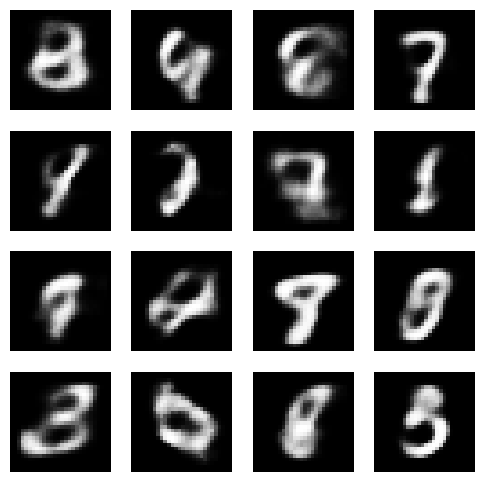

In [6]:
# TODO: Generate 16 new digits by sampling z ~ N(0,1) and passing through vae.decoder.
# Display them in a 4x4 grid using plt.imshow.
vae.eval()
with torch.no_grad():
    z = torch.randn(16, 16, device=device)
    samples = vae.decoder(z).cpu()

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, img in zip(axes.flat, samples):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.axis("off")
plt.show()

### ❓ Reflect — VAE
Answer in a markdown cell below:
1. Are the generated digits sharp or blurry? Why does this happen architecturally?
2. What does the KL divergence term in the loss do? What happens if you remove it?

Reflection:

1. The digits are blurry. The strokes look soft and smeared, and some look like a mix of two digits. This happens because the decoder is scored on each pixel separately and the latent code z is sampled with noise. When the decoder isnt sure what the exact image should be, the safest guess is the average of the possibilities and this gives gray and blurry pixels instead of sharp edges.

2. The KL term pushes the encoders outputs to stay close to a standard normal distribution. This keeps the latent space smooth and packed together so it decodes into something that looks like a digit. If you remove it, the model becomes a plain autoencoder. Its reconstructions get sharper but the latent space becomes scattered with gaps.



## Part 2 — GAN on MNIST
**Goal:** Train a GAN. Deliberately trigger mode collapse and document it.

In [7]:
class Generator(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 128), nn.ReLU(),
            nn.Linear(128, 256),   nn.ReLU(),
            nn.Linear(256, 784),   nn.Tanh(),
            nn.Unflatten(1, (1,28,28))
        )
    def forward(self, z): return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 1),   nn.Sigmoid()
        )
    def forward(self, x): return self.net(x)

Epoch 1: D loss = 1.023, G loss = 1.016
Epoch 2: D loss = 0.579, G loss = 2.222
Epoch 3: D loss = 0.619, G loss = 2.306
Epoch 4: D loss = 0.592, G loss = 2.635
Epoch 5: D loss = 0.480, G loss = 2.833
Epoch 6: D loss = 0.412, G loss = 3.796
Epoch 7: D loss = 0.330, G loss = 3.710
Epoch 8: D loss = 0.334, G loss = 3.966
Epoch 9: D loss = 0.300, G loss = 3.823
Epoch 10: D loss = 0.342, G loss = 4.008


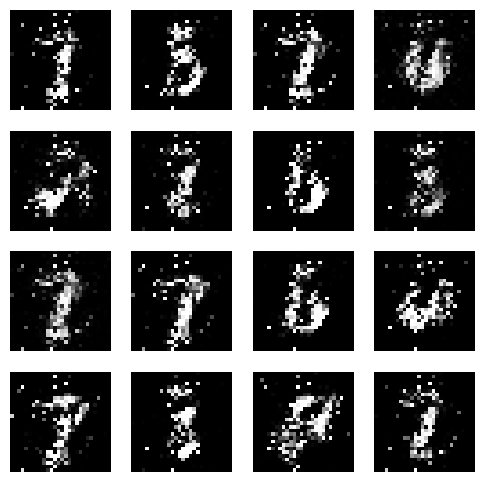

In [8]:
# TODO: Train the GAN for 10 epochs with BALANCED learning rates (lr=2e-4 for both G and D).
# Generate and display 16 images after training. These should show variety.
import torch.nn as nn

# Generator ends in Tanh, so scale real images to [-1, 1]
gan_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
gan_data = datasets.MNIST(root='./data', train=True, download=True, transform=gan_transform)
gan_loader = DataLoader(gan_data, batch_size=128, shuffle=True, drop_last=True)

def train_gan(lr_g, lr_d, epochs, z_dim=64):
    G, D = Generator(z_dim).to(device), Discriminator().to(device)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    bce = nn.BCELoss()
    for epoch in range(epochs):
        d_sum = g_sum = 0.0
        for real, _ in gan_loader:
            real = real.to(device)
            b = real.size(0)
            ones = torch.ones(b, 1, device=device)
            zeros = torch.zeros(b, 1, device=device)

            # Discriminator: real -> 1, fake -> 0
            fake = G(torch.randn(b, z_dim, device=device)).detach()
            d_loss = bce(D(real), ones) + bce(D(fake), zeros)
            opt_d.zero_grad(); d_loss.backward(); opt_d.step()

            # Generator: make D output 1 on fakes
            g_loss = bce(D(G(torch.randn(b, z_dim, device=device))), ones)
            opt_g.zero_grad(); g_loss.backward(); opt_g.step()

            d_sum += d_loss.item(); g_sum += g_loss.item()
        print(f"Epoch {epoch + 1}: D loss = {d_sum / len(gan_loader):.3f}, G loss = {g_sum / len(gan_loader):.3f}")
    return G

def gan_samples(G, n, z_dim=64):
    G.eval()
    with torch.no_grad():
        return ((G(torch.randn(n, z_dim, device=device)) + 1) / 2).cpu()   # back to [0, 1]

G_good = train_gan(lr_g=2e-4, lr_d=2e-4, epochs=10)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, img in zip(axes.flat, gan_samples(G_good, 16)):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.axis("off")
plt.show()

Epoch 1: D loss = 0.745, G loss = 1.497
Epoch 2: D loss = 0.527, G loss = 2.515
Epoch 3: D loss = 0.454, G loss = 2.851
Epoch 4: D loss = 0.428, G loss = 2.970
Epoch 5: D loss = 0.389, G loss = 3.054
Epoch 6: D loss = 0.383, G loss = 2.955
Epoch 7: D loss = 0.399, G loss = 2.846
Epoch 8: D loss = 0.392, G loss = 2.791
Epoch 9: D loss = 0.733, G loss = 2.508
Epoch 10: D loss = 0.461, G loss = 2.476


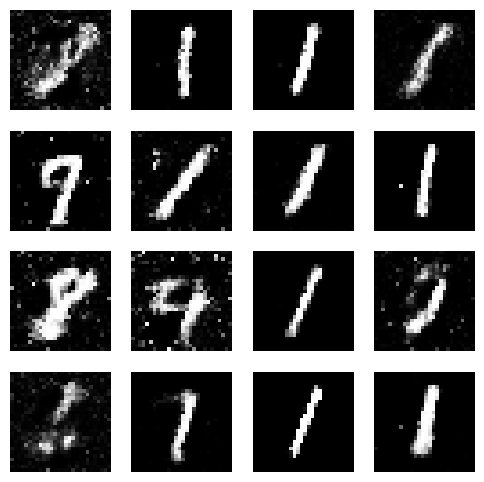

In [9]:
# TODO: Now TRIGGER MODE COLLAPSE: retrain with D learning rate 10x higher than G (e.g. D=2e-3, G=2e-4).
# Generate 16 images. Document what you see - do they all look the same?
G_collapsed = train_gan(lr_g=2e-4, lr_d=2e-3, epochs=10)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, img in zip(axes.flat, gan_samples(G_collapsed, 16)):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.axis("off")
plt.show()

### ❓ Reflect — GAN
1. Describe the mode collapse you triggered. What exactly happened visually?
2. Why does discriminator learning rate imbalance cause mode collapse? Explain the gradient flow.

Reflection:

1. Most of the 16 images look like a 1. The few that dont have white dots around them. So the generator has mostly collapsed onto one easy digit instead of producing all ten and the samples it makes outside that mode are low quality.

2. Basically when D learns 10x faster, it gets very good at spotting fakes and the feedback it gives G becomes weak and jumpy instead of a useful guide to what real digits look like. G then falls back on a few outputs that happen to fool D like the 1 and has no push to cover the other digits. D quickly learns to reject that pattern and G jumps to something slightly different so G never learns the full range of digits.

## Part 3 — FID Score Comparison
**Goal:** Compute FID for VAE and GAN outputs and interpret the result.

In [10]:
!pip install pytorch-fid --quiet

In [11]:
# TODO: Generate 1000 images from your VAE and 1000 from your GAN (post-collapse and pre-collapse versions).
# Save them to folders: ./vae_images/, ./gan_good/, ./gan_collapsed/
# Then compute FID: !python -m pytorch_fid ./real_images/ ./vae_images/
# Record the three FID scores.
import os
from torchvision.utils import save_image

def save_images(tensor, folder):
    os.makedirs(folder, exist_ok=True)
    for i, img in enumerate(tensor):
        save_image(img, f"{folder}/{i:04d}.png")

# 1000 real MNIST images (pixel range [0, 1])
os.makedirs("real_images", exist_ok=True)
for i in range(1000):
    save_image(train_data[i][0], f"real_images/{i:04d}.png")

vae.eval()
with torch.no_grad():
    vae_imgs = vae.decoder(torch.randn(1000, 16, device=device)).cpu()

save_images(vae_imgs, "vae_images")
save_images(gan_samples(G_good, 1000), "gan_good")
save_images(gan_samples(G_collapsed, 1000), "gan_collapsed")

print("VAE:")
!python -m pytorch_fid ./real_images/ ./vae_images/
print("GAN (good):")
!python -m pytorch_fid ./real_images/ ./gan_good/
print("GAN (collapsed):")
!python -m pytorch_fid ./real_images/ ./gan_collapsed/

VAE:
Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth
100% 91.2M/91.2M [00:00<00:00, 204MB/s]
100% 20/20 [00:06<00:00,  3.06it/s]
100% 20/20 [00:04<00:00,  4.81it/s]
FID:  74.49344658255723
GAN (good):
100% 20/20 [00:04<00:00,  4.42it/s]
100% 20/20 [00:04<00:00,  4.77it/s]
FID:  250.6536753697266
GAN (collapsed):
100% 20/20 [00:04<00:00,  4.42it/s]
100% 20/20 [00:04<00:00,  4.76it/s]
FID:  140.45321269583184


### ❓ Final Reflection — Production Decision
Your client needs **synthetic medical imaging data**. They have 300 labelled scans.

1. Which model (VAE or GAN) do you recommend and why?
2. What breaks first at 300 training examples?
3. What metric would you use to validate the synthetic data before using it for classifier training?

Answer here:

1. Id recommend the VAE because with only 300 scans, a GAN is hard to train because the discriminator quickly learns all 300 images and training becomes unstable. A VAE trains reliably and covers the full range of the data instead of collapsing onto a few examples.

2. For a GAN, the discriminator memorizes the small training set so the generator either copies real scans or training falls apart. For a VAE, the model doesnt have enough data to learn detail so outputs come out blurry and can miss small features.

3. Id train a classifier on the synthetic data and test it on real scans it has never seen and then check how it performs. FID is a poor choice here because its unreliable with so few images and it only says the images look similar, not that they are actually useful.

---
## Submission
- [ ] Push to `genai-course/week1/lab1.ipynb`
- [ ] All TODO cells completed and run
- [ ] Reflection questions answered
- [ ] Best generated image grid in README